# Plot DM density profiles
This notebook describes how to generate a radial/angular profile of the dark matter density previously generated with `CLUMPY`. It needs an input file `Density_dsph_parameters_14.csv` which is in the folder as well as the actual density profiles parameters in `./../clumpy/DMdensity`

Authors: Gonzalo Rodriguez Fernandez gonzalo.rodriguez.fernandez@roma2.infn.it, Michele Doro michele.doro@unipd.it

Last update: 2025.07.17

#### General imports

In [1]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.offsetbox import AnchoredText
import pandas as pd
import numpy as np
import glob as glob
from scipy.interpolate import interp1d, make_interp_spline, BSpline

#### Definition of names and paths

In [2]:
#df_input = pd.read_csv('Density_dsph_parameters_all.csv')
df_input = pd.read_csv('Density_dsph_parameters_14.csv')

# dSph names
#completeName = df_input['completeName'].values 
dSphNames = df_input['dSphNames'].values 
dSphNames = np.array(['BooI', 'CBe', 'DraI', 'GruII', 'RetII', 'Scl',
       'Seg1', 'Sex', 'SgrI', 'SgrII', 'TriII', 'UMaII', 'UMi',
       'Wil1'])

# Other parameters
# - distance kpc
# - Rtidal_einasto: tidal radius according to Einasto profile in kpc
# - Rtidal_burkert: tidal radius according to Burkert profile in kpc
distance       = df_input['distance'].values 
Rtidal_einasto = df_input['Rtidal_einasto'].values 
Rtidal_burkert = df_input['Rtidal_burkert'].values 
alpha_opt      = df_input['alpha_opt'].values 
chi2_Einasto = df_input['chi2_Einasto'].values 
chi2_Burkert = df_input['chi2_Burkert'].values 
channels = ['b','Tau']

alpha_Einasto_tidal = np.rad2deg(np.arctan(np.divide(Rtidal_einasto,distance)))
alpha_Burkert_tidal = np.rad2deg(np.arctan(np.divide(Rtidal_burkert,distance)))

df_input.head()

,Unnamed: 0,dSphNames,distance,Rtidal_einasto,Rtidal_burkert,alpha_opt,chi2_Einasto,chi2_Burkert
0,0,BooI,65,5.10,15.1,0.81,1.000000,1.000000
1,1,CBe,42,6.30,19.0,0.20,1.467308,1.439623
2,2,DraI,75,4.83,4.3,0.23,1.391558,1.389849
3,3,GruII,53,0.35,9.5,0.36,1.000000,1.000000
4,4,RetII,32,1.70,5.8,0.15,1.954545,1.800000


In [3]:
dSphNames

array(['BooI', 'CBe', 'DraI', 'GruII', 'RetII', 'Scl', 'Seg1', 'Sex',
       'SgrI', 'SgrII', 'TriII', 'UMaII', 'UMi', 'Wil1'], dtype='<U5')

In [4]:
# Define paths for astrophysical profiles
path = "../../clumpy/DMdensity"
!ls -l {path}

total 944
-rw-r--r--  1 mdoro  staff   16623 Jul 18 13:35 dm_densityprofile_burkert_others.dat
-rw-r--r--  1 mdoro  staff  218476 Jul 18 13:35 dm_densityprofile_burkert.dat
-rw-r--r--  1 mdoro  staff   16548 Jul 18 13:35 dm_densityprofile_einasto_others.dat
-rw-r--r--  1 mdoro  staff  220762 Jul 18 13:35 dm_densityprofile_einasto.dat


#### Just read the files and check output

In [5]:
df_BurkertDensity = pd.read_csv(path+'/dm_densityprofile_burkert.dat',
                                sep='\s+',
                                comment='#'
                               )

df_BurkertDensity2 = pd.read_csv(path+'/dm_densityprofile_burkert_others.dat',
                                sep='\s+',
                                comment='#'
                               )

df_EinastoDensity = pd.read_csv(path+'/dm_densityprofile_einasto.dat',
                                sep='\s+',
                                comment='#'
                               )

df_EinastoDensity2 = pd.read_csv(path+'/dm_densityprofile_einasto_others.dat',
                                sep='\s+',
                                comment='#'
                               )

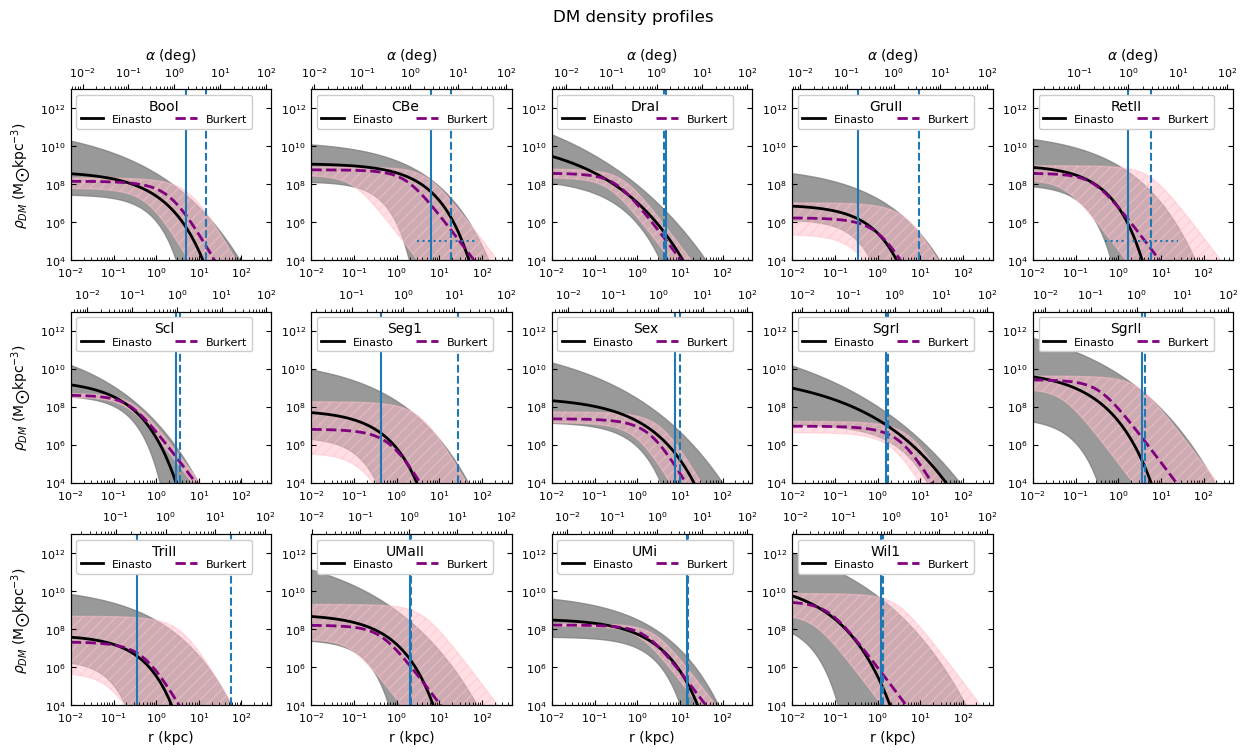

In [6]:
fig, ax_main = plt.subplots(3, 5, figsize=(15, 8))
plt.subplots_adjust(hspace=0.3)
fig.suptitle("DM density profiles")

counts = 1
for name, ax in zip(dSphNames, ax_main.flat):
    
   
    Rt_ein = Rtidal_einasto[counts-1]
    Rt_bur = Rtidal_burkert[counts-1]

    counts = counts + 1
    
    UP = name+'_UP'
    LO = name+'_LO'

    #print(name, UP, LO)
    if ((name== 'GruII') or (name=='BooI') or (name=='Seg1') or (name=='Sex') or (name=='SgrI') or (name=='TriII')):  
            ax.plot(df_EinastoDensity2['r'], df_EinastoDensity2[name], linewidth=2, color='black',  
                   label=r'Einasto')
            ax.plot(df_BurkertDensity2['r'], df_BurkertDensity2[name], linewidth=2, linestyle='--', color='purple',  
                     label=r'Burkert')
            ax.fill_between(df_EinastoDensity2['r'],
                             df_EinastoDensity2[UP],
                             df_EinastoDensity2[LO], color='grey', alpha=0.8)
            ax.fill_between(df_BurkertDensity2['r'],
                             df_BurkertDensity2[UP],
                             df_BurkertDensity2[LO], color='pink', alpha=0.5, hatch='///')
            ax2 = ax.twiny()
            x_angle = np.rad2deg(np.arctan(np.divide(df_EinastoDensity2['r'],distance[counts-2])))
            ax2.plot(x_angle,df_EinastoDensity2[name], linewidth=0)
            ax2.loglog()
    else:
            ax.plot(df_EinastoDensity['r'], df_EinastoDensity[name], linewidth=2, color='black',  
                label=r'Einasto')
            ax.plot(df_BurkertDensity['r'], df_BurkertDensity[name], linewidth=2, linestyle='--', color='purple',  
                 label=r'Burkert')
            ax.fill_between(df_EinastoDensity['r'],
                         df_EinastoDensity[UP],
                         df_EinastoDensity[LO], color='grey', alpha=0.8)
            ax.fill_between(df_BurkertDensity['r'],
                         df_BurkertDensity[UP],
                         df_BurkertDensity[LO], color='pink', alpha=0.5, hatch='///')
            ax2 = ax.twiny()
            x_angle = np.rad2deg(np.arctan(np.divide(df_EinastoDensity['r'],distance[counts-2]))) 
            ax2.plot(x_angle,df_EinastoDensity[name], linewidth=0) 
            ax2.loglog()            
   


    if name == 'CBe':
         ax.hlines(y = 1e5,  xmin=3, xmax=74, color = 'tab:blue', linestyle=':')

    if name == 'RetII':
         ax.hlines(y = 1e5, xmin=0.5, xmax=25.1, color = 'tab:blue', linestyle=':')
    
    if (counts-1 == 1 or counts-1 == 6 or counts-1 == 11 ):
        ax.set_ylabel(r"$\rho_{DM}$ (M$_{\bigodot}$kpc$^{-3}$)", fontsize=10)


    # Compute a 2nd axis with distances instead of angles
    

    if counts-1 <= 5:
         ax2.set_xlabel(r"$\alpha$ (deg)", fontsize=10)
    if counts-1 >= 11:
         ax.set_xlabel(r"r (kpc)", fontsize=10)
        
    #ax.set_xlabel(r"r (kpc)", fontsize=10)
    if counts-1 <= 14:
        ax.set_ylim(1e4, 1e13)
        ax.set_xlim(0.01,500)
        ax.loglog()
        ax.tick_params(which='both', direction='in', top=False, right=True)
        ax.axvline(x = Rt_ein, color = 'tab:blue', linestyle='-')
        ax.axvline(x = Rt_bur, color = 'tab:blue', linestyle='--')
        legend = ax.legend(title=name, fontsize=8, loc='upper left', facecolor='white', framealpha=1, labelspacing=0.1, ncols=2)
        
#     if counts-1==1:
#           lines = ax.get_lines()
#           legend2 = ax.legend([lines[i] for i in [2,3]], ["Tidal r. (Ein)", "Tidal r. (Bur)"], loc="center right", labelspacing=0.1)
#           ax.add_artist(legend2)

     # Adjust tick label size and padding
    ax.tick_params(axis='both', which='major', labelsize=8, pad=4)
    ax2.tick_params(axis='both', which='major', labelsize=8, pad=4)
     
    


ax_main[-1, -1].axis('off')
ax_main[-1, -1].set_facecolor('white')


    
#plt.savefig('plot_profiles_density_14.png', bbox_inches='tight', pad_inches=.3)


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that 

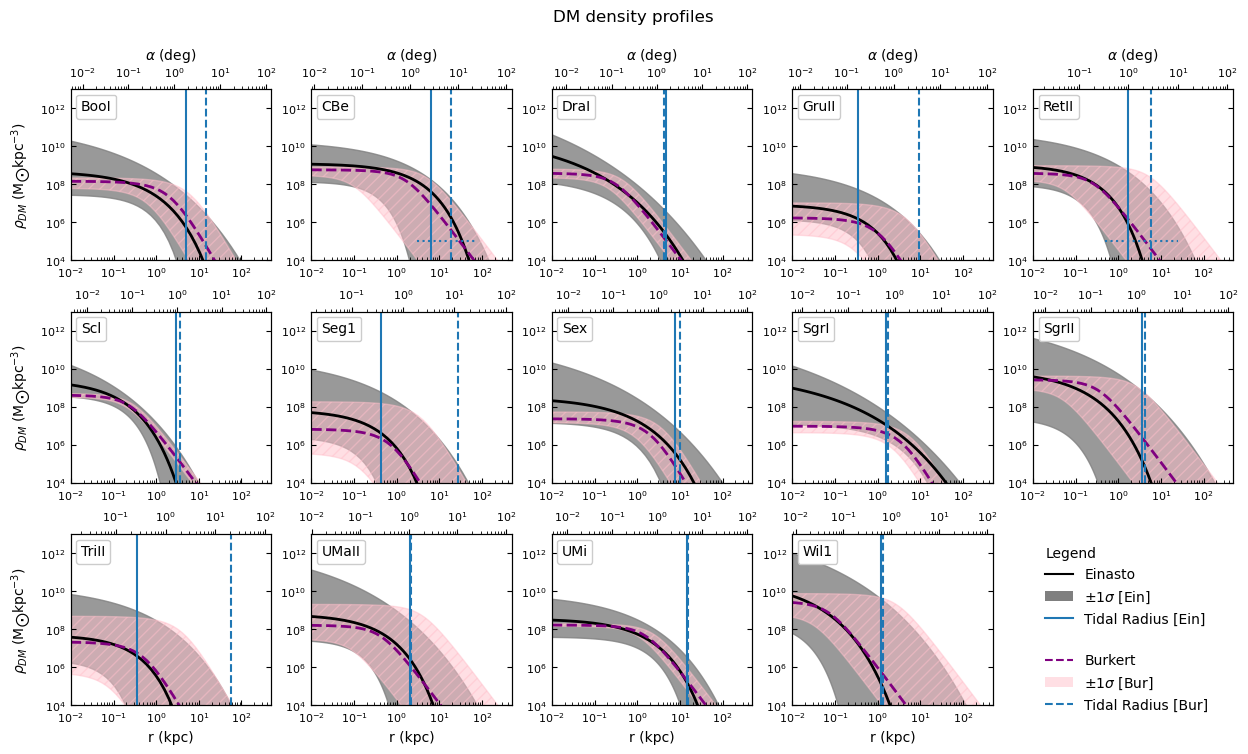

In [9]:
## Version 2 with legend on the empty pad

fig, ax_main = plt.subplots(3, 5, figsize=(15, 8))
plt.subplots_adjust(hspace=0.3)
fig.suptitle("DM density profiles")

counts = 1
for name, ax in zip(dSphNames, ax_main.flat):
    
   
    Rt_ein = Rtidal_einasto[counts-1]
    Rt_bur = Rtidal_burkert[counts-1]

    counts = counts + 1
    
    UP = name+'_UP'
    LO = name+'_LO'

    #print(name, UP, LO)
    if ((name== 'GruII') or (name=='BooI') or (name=='Seg1') or (name=='Sex') or (name=='SgrI') or (name=='TriII')):  
            ax.plot(df_EinastoDensity2['r'], df_EinastoDensity2[name], linewidth=2, color='black' )
            ax.plot(df_BurkertDensity2['r'], df_BurkertDensity2[name], linewidth=2, linestyle='--', color='purple')
            ax.fill_between(df_EinastoDensity2['r'],
                             df_EinastoDensity2[UP],
                             df_EinastoDensity2[LO], color='grey', alpha=0.8)
            ax.fill_between(df_BurkertDensity2['r'],
                             df_BurkertDensity2[UP],
                             df_BurkertDensity2[LO], color='pink', alpha=0.5, hatch='///')
            ax2 = ax.twiny()
            x_angle = np.rad2deg(np.arctan(np.divide(df_EinastoDensity2['r'],distance[counts-2])))
            ax2.plot(x_angle,df_EinastoDensity2[name], linewidth=0)
            ax2.loglog()
    else:
            ax.plot(df_EinastoDensity['r'], df_EinastoDensity[name], linewidth=2, color='black')
            ax.plot(df_BurkertDensity['r'], df_BurkertDensity[name], linewidth=2, linestyle='--', color='purple')
            ax.fill_between(df_EinastoDensity['r'],
                         df_EinastoDensity[UP],
                         df_EinastoDensity[LO], color='grey', alpha=0.8)
            ax.fill_between(df_BurkertDensity['r'],
                         df_BurkertDensity[UP],
                         df_BurkertDensity[LO], color='pink', alpha=0.5, hatch='///')
            ax2 = ax.twiny()
            x_angle = np.rad2deg(np.arctan(np.divide(df_EinastoDensity['r'],distance[counts-2]))) 
            ax2.plot(x_angle,df_EinastoDensity[name], linewidth=0) 
            ax2.loglog()            
   


    if name == 'CBe':
         ax.hlines(y = 1e5,  xmin=3, xmax=74, color = 'tab:blue', linestyle=':')

    if name == 'RetII':
         ax.hlines(y = 1e5, xmin=0.5, xmax=25.1, color = 'tab:blue', linestyle=':')
    
    if (counts-1 == 1 or counts-1 == 6 or counts-1 == 11 ):
        ax.set_ylabel(r"$\rho_{DM}$ (M$_{\bigodot}$kpc$^{-3}$)", fontsize=10)


    # Compute a 2nd axis with distances instead of angles
    

    if counts-1 <= 5:
         ax2.set_xlabel(r"$\alpha$ (deg)", fontsize=10)
    if counts-1 >= 11:
         ax.set_xlabel(r"r (kpc)", fontsize=10)
     
        
    #ax.set_xlabel(r"r (kpc)", fontsize=10)
    if counts-1 <= 14:
        ax.set_ylim(1e4, 1e13)
        ax.set_xlim(0.01,500)
        ax.loglog()
        ax.tick_params(which='both', direction='in', top=False, right=True)
        ax.axvline(x = Rt_ein, color = 'tab:blue', linestyle='-')
        ax.axvline(x = Rt_bur, color = 'tab:blue', linestyle='--')
        legend = ax.legend(title=name, fontsize=8, loc='upper left', facecolor='white', framealpha=1, labelspacing=0.1, ncols=2)
        
#     if counts-1==1:
#           lines = ax.get_lines()
#           legend2 = ax.legend([lines[i] for i in [2,3]], ["Tidal r. (Ein)", "Tidal r. (Bur)"], loc="center right", labelspacing=0.1)
#           ax.add_artist(legend2)

     # Adjust tick label size and padding
    ax.tick_params(axis='both', which='major', labelsize=8, pad=4)
    ax2.tick_params(axis='both', which='major', labelsize=8, pad=4)
     
    


ax_main[-1, -1].axis('off')
ax_main[-1, -1].set_facecolor('white')

from matplotlib.lines import Line2D
from matplotlib.patches import Patch


# Use last axis (bottom-right) for the legend
handles = [
    Line2D([0], [0], color='black', label='Einasto'),
    Patch(facecolor='black', alpha=0.5, label=r'$\pm1\sigma$ [Ein]'),   # fascia grigia
    Line2D([0], [0], color='tab:blue', linestyle='-', label='Tidal Radius [Ein]'),
    Patch(facecolor='white', alpha=0.3),
    Line2D([0], [0], color='purple', linestyle='--', label='Burkert'),
    Patch(facecolor='pink', alpha=0.5, label=r'$\pm1\sigma$ [Bur]' ),   # fascia rosa/viola
    Line2D([0], [0], color='tab:blue', linestyle='--', label='Tidal Radius [Bur]')
]
#ax_main[3, 3].axis('off')  # hide the empty subplot
#ax_main[-1, -1].legend(title="Legend", handles=handles, loc='upper left', frameon=False)

legend = ax_main[-1, -1].legend(title="Legend", handles=handles, loc='upper left', frameon=False)
legend.get_title().set_ha('left')
legend._legend_box.align = "left"  # Optional, aligns content to the left



    
plt.savefig('plot_profiles_density_14.png', bbox_inches='tight', pad_inches=.3)
